# 11 Migration of the swarm: diffusion front and back front

**The physical picture.** If pore pressure spreading from a source drives a swarm, events start near the source and migrate outward. The farthest events at time $t$ then lie near the triggering front

$$r^2 = 4\pi D t,$$

where $D$ is the hydraulic diffusivity (Shapiro et al., 1997). If the pressure source stops at time $t_0$, a seismicity-free zone can open behind the source and grow outward: the back front (Parotidis et al., 2004),

$$r_{bf} = \sqrt{4 D t\,(t/t_0 - 1)\,\ln\!\left(\tfrac{t}{t - t_0}\right)}, \quad t > t_0.$$

**Catalog.** The 101 events of the joint relocation that meet the 25 m rule (notebook 10: 28 references and 73 FMF detections). Distances are measured in the fitted plane from the first event, a proxy for where the driving pressure entered; the out-of-plane component is discarded.

**Methods.** Haenam's methods are applied unchanged.
- **Front (the report's protocol).** Within a fit window, the front-setting events are those that set a new running maximum of $r$. $D$ is the least-squares fit through the origin of $r^2 = 4\pi D t$ on those events. Ranges come from the least-squares 95 % interval and from 2,000 event bootstraps that re-select the front.
- **Back front (`joint_backfront.py`).** A low quantile of $r$ is taken in each time bin with at least 5 events, and at least 4 bins are required. $D$ is solved analytically at each trial $t_0$, and $t_0$ is profiled over a grid. Ranges come from 300 resamples stratified within bins.

**Time scale (decision D24).** Haenam's settings were made for sequences lasting weeks: an 8-day front window, 2-day bins and $t_0$ searched over 0.05–12 days. The Imsil swarm lasts 4.8 hours, so the settings are rescaled:
- front window 2 hours by default, with 0.5, 1 and 4.84 hours shown;
- back-front bins of 15 minutes by default, with 10 and 20 minutes shown;
- $t_0$ searched over 1 minute to 3 hours.

In [1]:
import os, sys
import numpy as np, pandas as pd
from scipy import stats as sps
from scipy.optimize import minimize_scalar
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt
pd.set_option('display.width', 220)
ev = pd.read_csv(f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv', dtype={'event_id': str}); ev['time'] = pd.to_datetime(ev.origin_time_reloc)
ev = ev.sort_values('time').reset_index(drop=True)
lat0, lon0 = ev.latitude.mean(), ev.longitude.mean()
ev['E'] = (ev.longitude - lon0) * 111.19 * np.cos(np.radians(lat0)) * 1000; ev['N'] = (ev.latitude - lat0) * 111.19 * 1000; ev['D'] = (ev.depth_km - ev.depth_km.mean()) * 1000
# the plane: Haenam's SVD fit (joint_science.plane, verbatim, as in notebooks 04 and 10)
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
P = plane(ev[['E', 'N', 'D']].to_numpy()); STRIKE, DIP = P['strike'], P['dip']
# in-plane coordinates, as Haenam's F07 builds them
cen = P['center']; phi, dl = np.radians(STRIKE), np.radians(DIP)
u_s = np.array([np.sin(phi), np.cos(phi), 0.0]); u_d = np.array([np.cos(phi) * np.cos(dl), -np.sin(phi) * np.cos(dl), np.sin(dl)]); n_v = np.cross(u_s, u_d)
R = ev[['E', 'N', 'D']].to_numpy() - cen; Rp = R - np.outer(R @ n_v, n_v)
ev['along'], ev['down_dip'] = Rp @ u_s, Rp @ u_d
first = ev.iloc[0]
ev['ts'] = (ev.time - first.time).dt.total_seconds() / 86400.0          # elapsed DAYS (the unit of Haenam's functions)
ev['r'] = np.hypot(ev.along - first.along, ev.down_dip - first.down_dip)
print(f'{len(ev)} events ({int((ev.kind == "reference").sum())} references, {int((ev.kind == "detection").sum())} detections); plane {STRIKE:.1f} / {DIP:.1f}')
print(f'first event {first.event_id} ({first.kind}) at {first.time}; last at {ev.time.iloc[-1]} ({ev.ts.iloc[-1] * 24:.2f} h later); max in-plane distance {ev.r.max():.0f} m')

101 events (28 references, 73 detections); plane 268.7 / 88.2
first event 20251102200328 (detection) at 2025-11-02 20:03:28.800000; last at 2025-11-03 00:53:41.750000 (4.84 h later); max in-plane distance 239 m


## 1. Triggering front: $r^2 = 4\pi D t$ through the front-setting events

In [2]:
def front_fit(ts, r):
    "record-breaking events within the fit window -> D (m^2/s) through the origin, its LS standard error, the front indices"
    w = (ts > 0) & (ts <= FIT_D)
    o = np.argsort(ts[w]); tw, rw = ts[w][o], r[w][o]
    isf = rw >= np.maximum.accumulate(rw)
    tf, rf = tw[isf], rw[isf]; X = 4 * np.pi * tf * 86400.0
    Dv = float((X * rf ** 2).sum() / (X ** 2).sum())
    se = float(np.sqrt(((rf ** 2 - X * Dv) ** 2).sum() / max(len(tf) - 1, 1) / (X ** 2).sum()))
    return Dv, se, np.flatnonzero(w)[o][isf]
NBOOT = 2000; rng = np.random.default_rng(7); ts, r = ev.ts.to_numpy(), ev.r.to_numpy(); FRONT = {}
for hours in (0.5, 1.0, 2.0, 4.84):
    FIT_D = hours / 24.0
    Dv, se, idx = front_fit(ts, r); w = np.flatnonzero((ts > 0) & (ts <= FIT_D))
    Db = np.asarray([front_fit(ts[k], r[k])[0] for k in (rng.choice(w, len(w), replace=True) for _ in range(NBOOT))])
    ci95 = float(sps.t.ppf(0.975, max(len(idx) - 1, 1)) * se)
    FRONT[hours] = dict(window_h=hours, D_m2_s=Dv, LS_ci95=ci95, boot_lo=np.percentile(Db, 2.5), boot_hi=np.percentile(Db, 97.5), n_front=len(idx), n_window=len(w), idx=idx)
ft = pd.DataFrame(FRONT).T.drop(columns='idx'); display(ft.astype({'n_front': int, 'n_window': int}).round(4))
F = FRONT[2.0]
print(f'default (2 h window): D = {F["D_m2_s"]:.3f} m2/s +/- {F["LS_ci95"]:.3f} (LS 95 %), bootstrap {F["boot_lo"]:.3f}-{F["boot_hi"]:.3f}; {F["n_front"]} front-setting of {F["n_window"]} events')

,window_h,D_m2_s,LS_ci95,boot_lo,boot_hi,n_front,n_window
0.50,0.5,0.499736,0.174412,0.418355,0.742956,10,41
1.00,1.0,0.585742,0.103849,0.421385,0.674034,15,65
2.00,2.0,0.626715,0.087753,0.482876,0.685712,16,84
4.84,4.84,0.320654,0.079411,0.274305,0.667317,17,100


default (2 h window): D = 0.627 m2/s +/- 0.088 (LS 95 %), bootstrap 0.483-0.686; 16 front-setting of 84 events


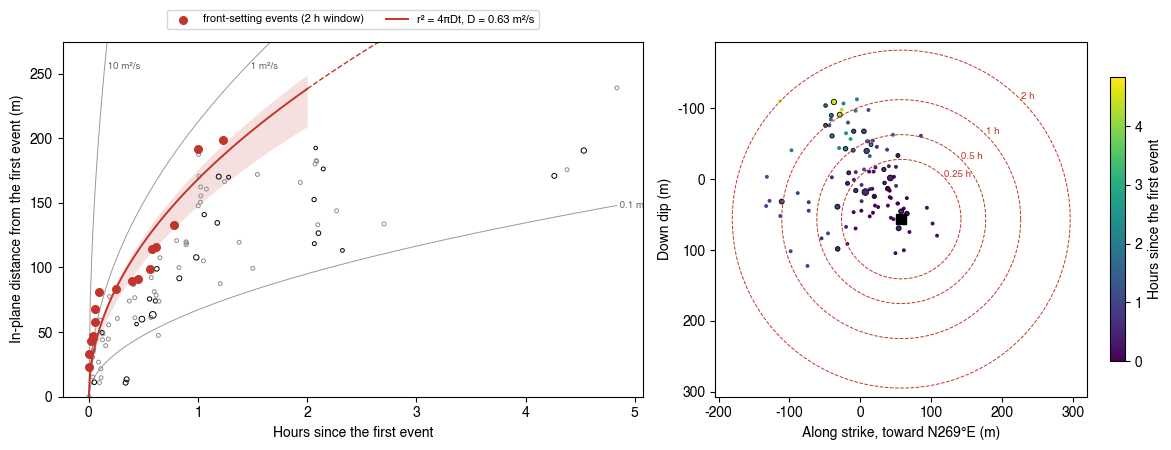

In [3]:
ml = ev.KMA_ML.fillna(np.nan); size = np.where(ml.notna(), 6 + 14 * (ml.fillna(1) - 0.8) ** 2, 8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
th = np.linspace(0, ev.ts.max() * 24, 400)
YMAX = ev.r.max() * 1.15
for Dr in (0.1, 1.0, 10.0):
    rr_ = np.sqrt(4 * np.pi * Dr * th * 3600); ax[0].plot(th, rr_, color='0.6', lw=0.7)
    k = np.searchsorted(rr_, 0.93 * YMAX); k = min(k, len(th) - 1)               # label where the curve leaves the panel (or at its end)
    ax[0].text(th[k], min(rr_[k], 0.93 * YMAX), f' {Dr:g} m²/s', fontsize=7, va='center', ha='left', color='0.4', clip_on=True)
inw = ev.ts * 24 <= 2.0
ax[0].scatter(ev.ts * 24, ev.r, s=size, facecolor=np.where(inw, 'none', 'none'), edgecolor=np.where(ev.kind == 'reference', 'black', '0.55'), lw=0.7, zorder=2)
ax[0].scatter(ev.ts.iloc[F['idx']] * 24, ev.r.iloc[F['idx']], s=30, color='#c1352b', zorder=3, label='front-setting events (2 h window)')
tt = np.linspace(0, 2.0, 200); ax[0].plot(tt, np.sqrt(4 * np.pi * F['D_m2_s'] * tt * 3600), color='#c1352b', lw=1.4, label=f'r² = 4πDt, D = {F["D_m2_s"]:.2f} m²/s')
ax[0].fill_between(tt, np.sqrt(4 * np.pi * F['boot_lo'] * tt * 3600), np.sqrt(4 * np.pi * F['boot_hi'] * tt * 3600), color='#c1352b', alpha=0.15, lw=0)
tt2 = np.linspace(2.0, ev.ts.max() * 24, 200); ax[0].plot(tt2, np.sqrt(4 * np.pi * F['D_m2_s'] * tt2 * 3600), color='#c1352b', lw=1, ls='--')
ax[0].set_xlabel('Hours since the first event'); ax[0].set_ylabel('In-plane distance from the first event (m)'); ax[0].set_ylim(0, YMAX)
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8)
sc = ax[1].scatter(ev.along, ev.down_dip, c=ev.ts * 24, cmap='viridis', s=size, edgecolor=np.where(ev.kind == 'reference', 'black', 'none'), lw=0.6)
ax[1].plot(first.along, first.down_dip, 's', color='black', ms=7)
for hh in (0.25, 0.5, 1.0, 2.0):
    rr = np.sqrt(4 * np.pi * F['D_m2_s'] * hh * 3600); ang = np.linspace(0, 2 * np.pi, 200)
    ax[1].plot(first.along + rr * np.cos(ang), first.down_dip + rr * np.sin(ang), color='#c1352b', lw=0.7, ls='--'); ax[1].text(first.along + rr * 0.71, first.down_dip - rr * 0.71, f'{hh:g} h', fontsize=7, color='#c1352b')
ax[1].invert_yaxis(); ax[1].set_aspect('equal', adjustable='datalim'); ax[1].set_xlabel(f'Along strike, toward N{STRIKE:.0f}°E (m)'); ax[1].set_ylabel('Down dip (m)')
fig.colorbar(sc, ax=ax[1], shrink=0.8, label='Hours since the first event'); plt.tight_layout(); plt.show()

## 2. Back front: the lower envelope after the source stops

In [4]:
def shape(t,t0):
    t=np.asarray(t,float);z=np.zeros_like(t);m=t>t0;u=t[m];z[m]=4*u*86400*(u/t0-1)*np.log1p(t0/(u-t0));return np.sqrt(z)

def radial(g,anchor=None):
    q=g.sort_values('time').copy();a=q.iloc[0] if anchor is None else anchor;q['elapsed']=(q.time-a.time).dt.total_seconds()/86400;q['radius']=np.hypot(q.along-a.along,q.down_dip-a.down_dip);return q,a

def bins(q,width=2,quantile=.1):
    rows=[]
    for key,g in q.groupby(np.floor(q.elapsed/width)):
        if len(g)>=5:rows.append(dict(time=float(g.elapsed.median()),radius=float(g.radius.quantile(quantile)),n=len(g),start=float(key*width),end=float((key+1)*width)))
    return pd.DataFrame(rows,columns=['time','radius','n','start','end'])

def fit(b,grid=np.linspace(.05,12,400)):
    # Haenam's fit; the t0 grid (days) is an argument here (D24) instead of the fixed 0.05-12 days
    if len(b)<4:return dict(status='insufficient_bins',n_bins=len(b))
    t=b.time.to_numpy();r=b.radius.to_numpy()
    def at(t0):
        s=shape(t,t0);a=max(float(s@r/(s@s)),0) if s@s else 0;return float(np.mean((a*s-r)**2)),a*a
    loss=np.array([at(z)[0] for z in grid]);i=int(loss.argmin());opt=minimize_scalar(lambda z:at(z)[0],bounds=(grid[max(0,i-1)],grid[min(len(grid)-1,i+1)]),method='bounded');mse,D=at(opt.x)
    h=np.sqrt(4*t*86400);amp=float(h@r/(h@h));simple=np.sqrt(np.mean((amp*h-r)**2))
    return dict(status='fit',n_bins=len(b),t0_days=float(opt.x),D_m2_s=D,RMSE_m=np.sqrt(mse),lower_bound=i==0,upper_bound=i==len(grid)-1,sqrt_t_RMSE_m=simple,RMSE_improvement_m=simple-np.sqrt(mse),profile=pd.DataFrame(dict(t0_days=grid,RMSE_m=np.sqrt(loss),D_m2_s=[at(z)[1] for z in grid])))
GRID = np.linspace(1 / 1440, 3 / 24, 400)                                 # t0 from 1 minute to 3 hours (days)
q, a = radial(ev)
rows = []; FITS = {}
for wmin in (10, 15, 20):
    for quant in (0, .1, .2):
        b = bins(q, wmin / 1440, quant); f = fit(b, GRID); FITS[wmin, quant] = (b, f)
        rows.append(dict(bin_min=wmin, quantile=quant, status=f['status'], n_bins=f.get('n_bins'), t0_min=f.get('t0_days', np.nan) * 1440, D_m2_s=f.get('D_m2_s', np.nan),
                         RMSE_m=f.get('RMSE_m', np.nan), t0_at_grid_edge=bool(f.get('lower_bound', False) or f.get('upper_bound', False)), RMSE_gain_over_sqrt_t_m=f.get('RMSE_improvement_m', np.nan)))
bf = pd.DataFrame(rows); display(bf.round(3))

,bin_min,quantile,status,n_bins,t0_min,D_m2_s,RMSE_m,t0_at_grid_edge,RMSE_gain_over_sqrt_t_m
0,10,0.0,fit,9,5.875,0.545,20.145,False,1.232
1,10,0.1,fit,9,2.751,0.683,22.517,False,0.332
2,10,0.2,fit,9,1.124,0.836,18.441,True,0.023
3,15,0.0,fit,6,24.347,0.610,8.855,False,11.674
4,15,0.1,fit,6,24.287,0.790,14.098,False,7.470
5,15,0.2,fit,6,1.641,0.756,16.867,False,0.061
6,20,0.0,fit,5,33.629,0.654,13.289,False,11.369
7,20,0.1,fit,5,3.083,0.603,15.885,False,0.430
8,20,0.2,fit,5,1.118,0.742,20.164,True,0.017


default back front (15-min bins, 10th percentile): t0 = 24.3 min, D = 0.790 m2/s; stratified resamples (300): t0 1.0-25.9 min, D 0.572-1.025 m2/s; t0 at the grid edge in 6 %
events after t0 inside the fitted back front: 12 of 65; RMSE 14.1 m vs 21.6 m for r = a*sqrt(t) (gain 7.5 m)


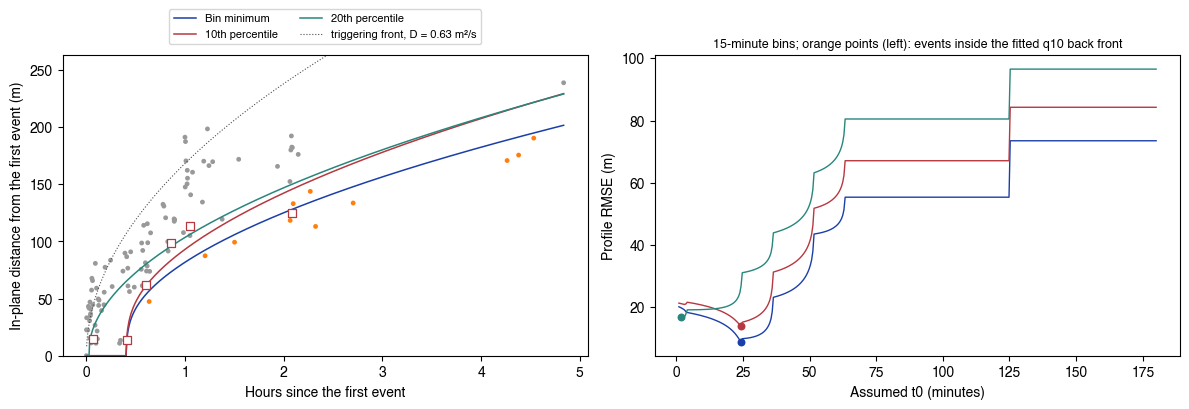

In [5]:
b, f = FITS[15, .1]; rngb = np.random.default_rng(28031); groups = [z for _, z in q.groupby(np.floor(q.elapsed / (15 / 1440)))]; bs = []
for n in range(300):
    sample = pd.concat([z.iloc[rngb.integers(0, len(z), len(z))] for z in groups]); rr_ = fit(bins(sample, 15 / 1440, .1), GRID)
    if rr_['status'] == 'fit': bs.append([rr_['t0_days'] * 1440, rr_['D_m2_s'], rr_['lower_bound'] or rr_['upper_bound']])
bs = np.array(bs, dtype=float); edge_share = bs[:, 2].mean() if len(bs) else np.nan
pred = np.sqrt(f['D_m2_s']) * shape(q.elapsed, f['t0_days']); post = q.elapsed.to_numpy() > f['t0_days']; inside = (q.radius.to_numpy() < pred) & post
print(f'default back front (15-min bins, 10th percentile): t0 = {f["t0_days"] * 1440:.1f} min, D = {f["D_m2_s"]:.3f} m2/s; stratified resamples ({len(bs)}): '
      f't0 {np.percentile(bs[:, 0], 2.5):.1f}-{np.percentile(bs[:, 0], 97.5):.1f} min, D {np.percentile(bs[:, 1], 2.5):.3f}-{np.percentile(bs[:, 1], 97.5):.3f} m2/s; t0 at the grid edge in {edge_share * 100:.0f} %')
print(f'events after t0 inside the fitted back front: {int(inside.sum())} of {int(post.sum())}; RMSE {f["RMSE_m"]:.1f} m vs {f["sqrt_t_RMSE_m"]:.1f} m for r = a*sqrt(t) (gain {f["RMSE_improvement_m"]:.1f} m)')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(q.elapsed * 24, q.radius, s=12, c=np.where(inside, 'tab:orange', '0.6'), edgecolors='none', zorder=1)
tt = np.linspace(1e-4, q.elapsed.max(), 800)
for (quant, col) in zip((0, .1, .2), ('#1b3fa8', '#b63840', '#28867c')):
    bb, ff = FITS[15, quant]
    if ff['status'] != 'fit': continue
    ax[0].plot(tt * 24, np.sqrt(ff['D_m2_s']) * shape(tt, ff['t0_days']), color=col, lw=1.1, label='Bin minimum' if quant == 0 else f'{int(quant * 100)}th percentile')
    if quant == .1: ax[0].scatter(bb.time * 24, bb.radius, marker='s', s=28, facecolors='white', edgecolors=col, lw=0.9, zorder=3)
    p = ff['profile']; ax[1].plot(p.t0_days * 1440, p.RMSE_m, color=col, lw=1); ax[1].scatter(ff['t0_days'] * 1440, ff['RMSE_m'], color=col, s=22)
ax[0].plot(tt * 24, np.sqrt(4 * np.pi * F['D_m2_s'] * tt * 86400), color='0.3', lw=0.8, ls=':', label=f'triggering front, D = {F["D_m2_s"]:.2f} m²/s')
ax[0].set_xlabel('Hours since the first event'); ax[0].set_ylabel('In-plane distance from the first event (m)'); ax[0].set_ylim(0, q.radius.max() * 1.1)
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8)
ax[1].set_xlabel('Assumed t0 (minutes)'); ax[1].set_ylabel('Profile RMSE (m)'); ax[1].set_title('15-minute bins; orange points (left): events inside the fitted q10 back front', fontsize=9)
plt.tight_layout(); plt.show()

## Comprehensive summary

In [6]:
summary = pd.DataFrame([
    ('Catalog', f'{len(ev)} events meeting 25 m (notebook 10); first event {first.event_id} ({first.kind}) at {first.time:%H:%M:%S}'),
    ('Plane used for in-plane distances', f'{STRIKE:.1f} / {DIP:.1f}'),
    *[(f'Triggering front D, {h:g} h window (LS 95 %; bootstrap)', f'{FRONT[h]["D_m2_s"]:.3f} m²/s (± {FRONT[h]["LS_ci95"]:.3f}; {FRONT[h]["boot_lo"]:.3f}-{FRONT[h]["boot_hi"]:.3f}); {FRONT[h]["n_front"]} front events') for h in (0.5, 1.0, 2.0, 4.84)],
    ('Back front, 15-min bins, q10: t0; D', f'{f["t0_days"] * 1440:.1f} min ({np.percentile(bs[:, 0], 2.5):.0f}-{np.percentile(bs[:, 0], 97.5):.0f}); {f["D_m2_s"]:.3f} m²/s ({np.percentile(bs[:, 1], 2.5):.3f}-{np.percentile(bs[:, 1], 97.5):.3f})'),
    ('Back front: events inside after t0; RMSE gain over sqrt(t)', f'{int(inside.sum())} of {int(post.sum())}; {f["RMSE_improvement_m"]:.1f} m'),
    ('Back-front fits at the t0 grid edge (of 9 definitions)', int(bf.t0_at_grid_edge.sum())),
], columns=['quantity', 'value'])
display(summary)
print('Time-scale settings (front window, bin width, t0 grid) are decision D24 (user); the tables above give every alternative.')

,quantity,value
0,Catalog,101 events meeting 25 m (notebook 10); first e...
1,Plane used for in-plane distances,268.7 / 88.2
2,"Triggering front D, 0.5 h window (LS 95 %; boo...",0.500 m²/s (± 0.174; 0.418-0.743); 10 front ev...
3,"Triggering front D, 1 h window (LS 95 %; boots...",0.586 m²/s (± 0.104; 0.421-0.674); 15 front ev...
4,"Triggering front D, 2 h window (LS 95 %; boots...",0.627 m²/s (± 0.088; 0.483-0.686); 16 front ev...
5,"Triggering front D, 4.84 h window (LS 95 %; bo...",0.321 m²/s (± 0.079; 0.274-0.667); 17 front ev...
6,"Back front, 15-min bins, q10: t0; D",24.3 min (1-26); 0.790 m²/s (0.572-1.025)
7,Back front: events inside after t0; RMSE gain ...,12 of 65; 7.5 m
8,Back-front fits at the t0 grid edge (of 9 defi...,2


Time-scale settings (front window, bin width, t0 grid) are decision D24 (user); the tables above give every alternative.
